# Exploración de los viajes de MiBici 2025

**Materia:** Operaciones de aprendizaje automático (TC5061, Gpo 10)
**Equipo:** 38
**Fecha:** 14 de octubre de 2026

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mibici import config, features

## Datos procesados por la ingesta

In [2]:
viajes = pd.read_parquet(config.ARCHIVO_VIAJES)
estaciones = pd.read_parquet(config.ARCHIVO_ESTACIONES)
with open(config.ARCHIVO_MANIFIESTO, encoding="utf-8") as archivo:
    manifiesto = json.load(archivo)
print("Versión de los datos:", manifiesto["version_datos"])
print("Meses:", len(manifiesto["meses"]))
print("Viajes:", len(viajes))
print("Estaciones en la nomenclatura:", len(estaciones))
viajes.head()

Versión de los datos: 7aa5e436d887
Meses: 12
Viajes: 4414800
Estaciones en la nomenclatura: 484


,viaje_id,inicio,fin,origen_id,destino_id,duracion_min,origen_conocido,destino_conocido
0,37162342,2025-01-01 00:00:44,2025-01-01 00:11:29,211,395,10.750000,True,True
1,37162343,2025-01-01 00:04:11,2025-01-01 00:15:07,35,260,10.933333,True,True
2,37162344,2025-01-01 00:05:27,2025-01-01 00:15:23,35,260,9.933333,True,True
3,37162345,2025-01-01 00:07:47,2025-01-01 00:17:42,190,11,9.916667,True,True
4,37162346,2025-01-01 00:08:52,2025-01-01 00:18:10,273,8,9.300000,True,True


In [3]:
print("Registros crudos:", manifiesto["limpieza"]["registros_crudos"])
print("Descartados:", {clave: valor for clave, valor in manifiesto["limpieza"].items() if clave != "registros_crudos"})
viajes.dtypes

Registros crudos: 4532032
Descartados: {'sin_fecha_o_estacion': 0, 'duplicados': 0, 'duracion_negativa': 0, 'duracion_menor_1_min': 117226, 'duracion_mayor_24_h': 6, 'duplicados_entre_meses': 0}


viaje_id                     int64
inicio              datetime64[us]
fin                 datetime64[us]
origen_id                    int32
destino_id                   int32
duracion_min               float32
origen_conocido               bool
destino_conocido              bool
dtype: object

## Viajes por mes

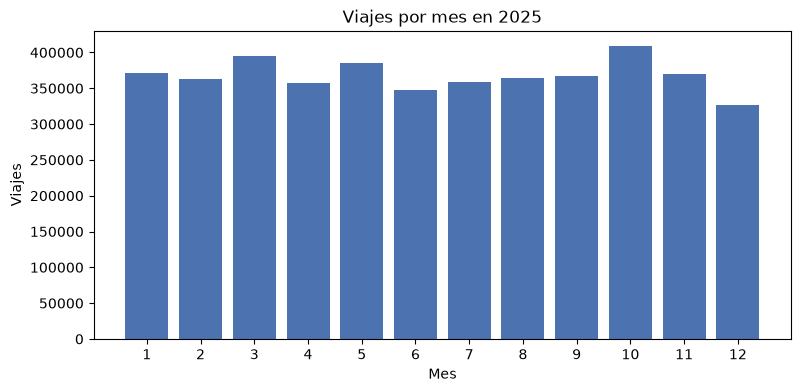

Promedio mensual: 367900 | mínimo: 326421 | máximo: 409540


In [4]:
mensual = viajes.groupby(viajes["inicio"].dt.month).size()
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(mensual.index, mensual.values, color="#4C72B0")
ax.set_title("Viajes por mes en 2025")
ax.set_xlabel("Mes")
ax.set_ylabel("Viajes")
ax.set_xticks(range(1, 13))
plt.show()
print("Promedio mensual:", int(mensual.mean()), "| mínimo:", int(mensual.min()), "| máximo:", int(mensual.max()))

## Viajes por hora del día

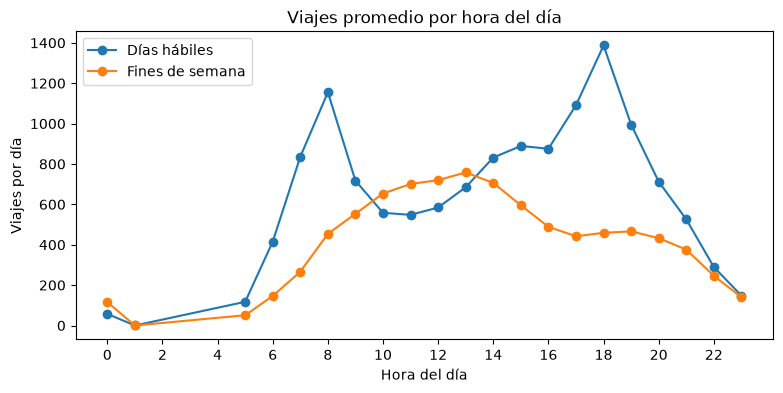

Hora pico en días hábiles: 18 | en fines de semana: 13


In [5]:
viajes["hora"] = viajes["inicio"].dt.hour
viajes["fin_de_semana"] = viajes["inicio"].dt.dayofweek >= 5
dias = viajes.groupby("fin_de_semana")["inicio"].apply(lambda s: s.dt.normalize().nunique())
por_hora = viajes.groupby(["fin_de_semana", "hora"]).size().unstack(0) / dias
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(por_hora.index, por_hora[False], marker="o", label="Días hábiles")
ax.plot(por_hora.index, por_hora[True], marker="o", label="Fines de semana")
ax.set_title("Viajes promedio por hora del día")
ax.set_xlabel("Hora del día")
ax.set_ylabel("Viajes por día")
ax.set_xticks(range(0, 24, 2))
ax.legend()
plt.show()
print("Hora pico en días hábiles:", int(por_hora[False].idxmax()), "| en fines de semana:", int(por_hora[True].idxmax()))

## Viajes por estación

In [6]:
salidas = viajes.groupby("origen_id").size().rename("salidas")
llegadas = viajes.groupby("destino_id").size().rename("llegadas")
actividad = estaciones.set_index("estacion_id").join(salidas).join(llegadas).fillna({"salidas": 0, "llegadas": 0})
print("Estaciones con viajes:", int((actividad["salidas"] + actividad["llegadas"] > 0).sum()))
print("Estaciones de la nomenclatura sin viajes en 2025:", int((actividad["salidas"] + actividad["llegadas"] == 0).sum()))
print("Estaciones con capacidad 0:", int((actividad["capacidad"] == 0).sum()))
actividad.loc[actividad["salidas"] > 0, "salidas"].describe().round(0)

Estaciones con viajes: 371
Estaciones de la nomenclatura sin viajes en 2025: 113
Estaciones con capacidad 0: 4


count      371.0
mean     11900.0
std      11163.0
min        120.0
25%       4485.0
50%       8629.0
75%      15880.0
max      84690.0
Name: salidas, dtype: float64

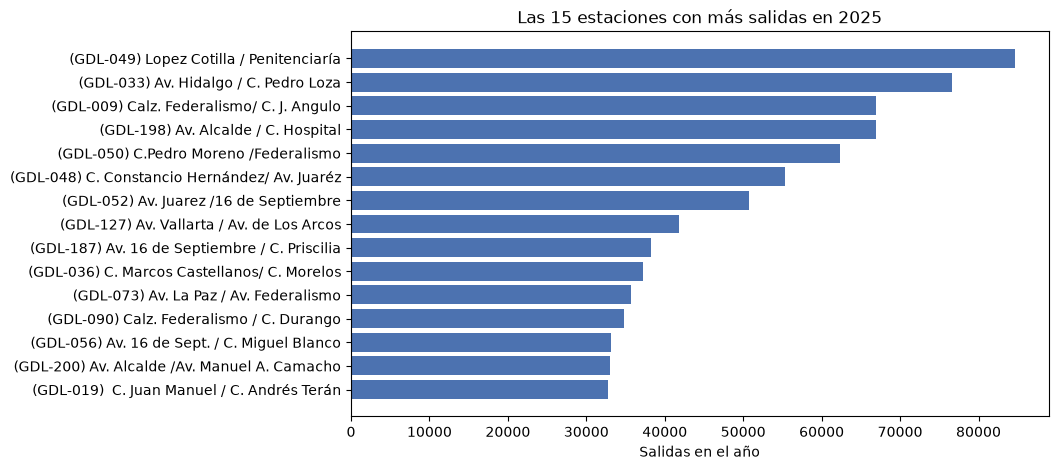

In [7]:
top = actividad.sort_values("salidas", ascending=False).head(15)
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(top["nombre"].str.slice(0, 45)[::-1], top["salidas"][::-1], color="#4C72B0")
ax.set_title("Las 15 estaciones con más salidas en 2025")
ax.set_xlabel("Salidas en el año")
plt.show()

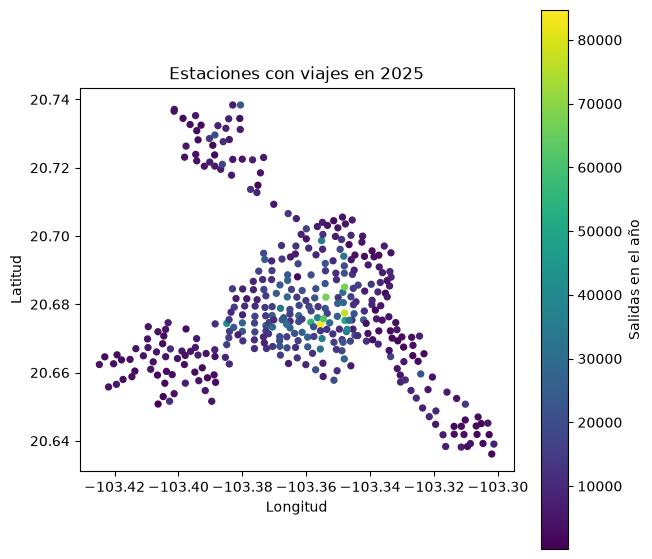

In [8]:
con_viajes = actividad[actividad["salidas"] > 0]
fig, ax = plt.subplots(figsize=(7, 7))
puntos = ax.scatter(con_viajes["longitud"], con_viajes["latitud"], c=con_viajes["salidas"], s=18, cmap="viridis")
ax.set_aspect(1 / np.cos(np.radians(con_viajes["latitud"].mean())))
ax.set_title("Estaciones con viajes en 2025")
ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")
plt.colorbar(puntos, ax=ax, label="Salidas en el año")
plt.show()

## Duración de los viajes

count    4414800.00
mean          11.44
std            8.56
min            1.00
5%             3.12
25%            6.15
50%            9.83
75%           15.13
95%           24.38
99%           32.93
max         1439.20
Name: duracion_min, dtype: float64


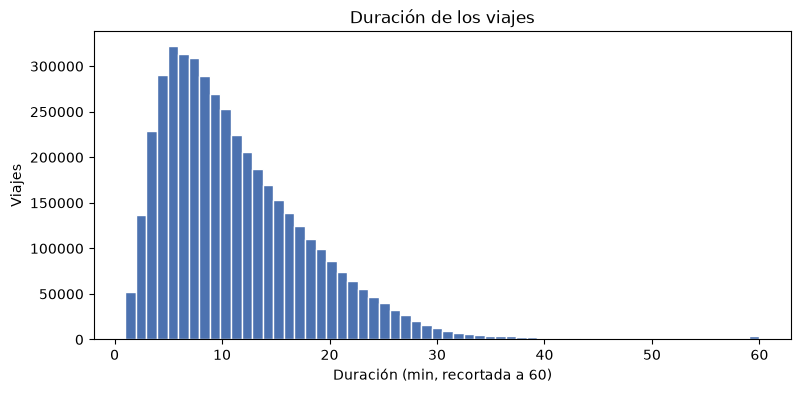

In [9]:
print(viajes["duracion_min"].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).round(2))
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(viajes["duracion_min"].clip(upper=60), bins=60, color="#4C72B0", edgecolor="white")
ax.set_title("Duración de los viajes")
ax.set_xlabel("Duración (min, recortada a 60)")
ax.set_ylabel("Viajes")
plt.show()

## Demanda diaria por estación (P1)

Registros estación-día: 134007
count    134007.0
mean         32.9
std          33.5
min           0.0
50%          23.0
90%          70.0
99%         177.0
max         550.0
Name: salidas, dtype: float64


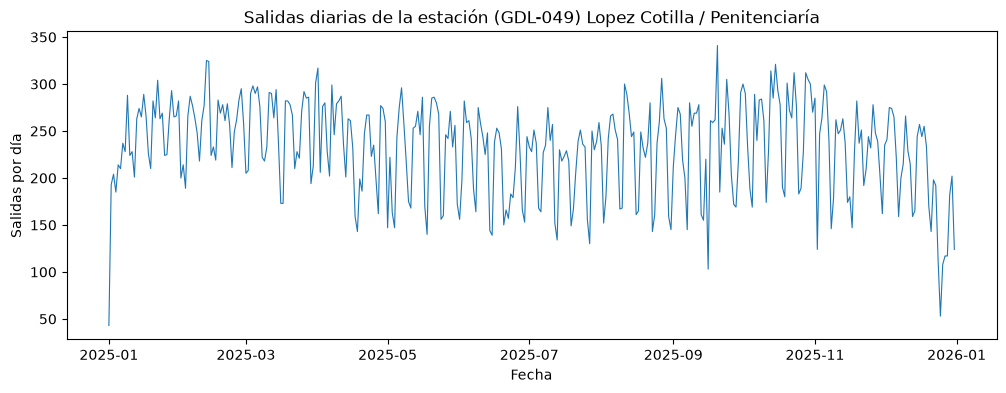

In [10]:
diario = features.viajes_por_estacion_y_dia(viajes)
print("Registros estación-día:", len(diario))
print(diario["salidas"].describe(percentiles=[0.5, 0.9, 0.99]).round(1))
estacion = salidas.idxmax()
serie = diario[diario["estacion_id"] == estacion].set_index("fecha")["salidas"]
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(serie.index, serie.values, linewidth=0.8)
ax.set_title("Salidas diarias de la estación " + estaciones.set_index("estacion_id").loc[estacion, "nombre"])
ax.set_xlabel("Fecha")
ax.set_ylabel("Salidas por día")
plt.show()

In [11]:
diario["dia_semana"] = diario["fecha"].dt.dayofweek
por_dia = diario.groupby("dia_semana")["salidas"].mean()
por_dia.index = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
por_dia.round(1)

Lun    35.2
Mar    37.8
Mié    37.4
Jue    36.8
Vie    35.5
Sáb    25.3
Dom    22.5
Name: salidas, dtype: float64

## Flujo neto por ventana de dos horas (P2)

Registros estación-hora en entrenamiento: 2401050
count    2401050.000
mean           0.093
std            0.138
min            0.000
50%            0.053
90%            0.263
95%            0.333
99%            0.600
max            3.947
dtype: float64


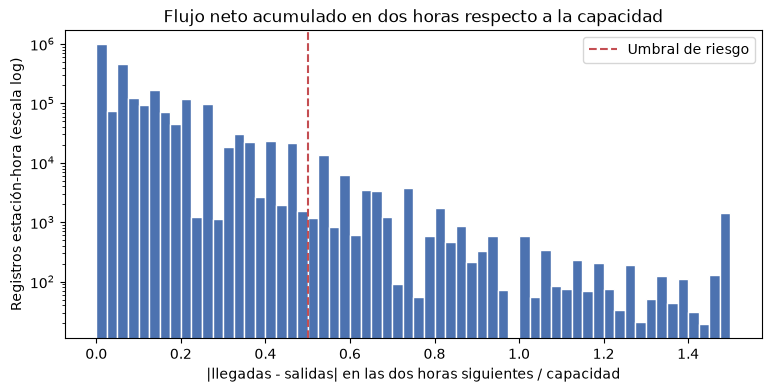

In [12]:
corte = pd.Timestamp(config.FIN_ENTRENAMIENTO) + pd.Timedelta(days=1)
entrenamiento = viajes[viajes["inicio"] < corte]
horario = features.flujo_por_estacion_y_hora(entrenamiento, estaciones)
etiquetado = features.etiquetar_riesgo(horario, estaciones)
razon = etiquetado["neto_futuro"].abs() / etiquetado["capacidad"]
print("Registros estación-hora en entrenamiento:", len(etiquetado))
print(razon.describe(percentiles=[0.5, 0.9, 0.95, 0.99]).round(3))
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(razon.clip(upper=1.5), bins=60, color="#4C72B0", edgecolor="white")
ax.axvline(config.UMBRAL_RIESGO, color="#C44E52", linestyle="--", label="Umbral de riesgo")
ax.set_yscale("log")
ax.set_title("Flujo neto acumulado en dos horas respecto a la capacidad")
ax.set_xlabel("|llegadas - salidas| en las dos horas siguientes / capacidad")
ax.set_ylabel("Registros estación-hora (escala log)")
ax.legend()
plt.show()

In [13]:
umbrales = [0.25, 0.3, 0.4, 0.5, 0.75, 1.0]
pd.DataFrame({
    "umbral": umbrales,
    "positivos": [int((razon >= u).sum()) for u in umbrales],
    "tasa_positivos_%": [round(float((razon >= u).mean()) * 100, 2) for u in umbrales],
})

,umbral,positivos,tasa_positivos_%
0,0.25,263391,10.97
1,0.30,166185,6.92
2,0.40,91778,3.82
3,0.50,42982,1.79
4,0.75,8770,0.37
5,1.00,3897,0.16


Umbral: 0.5 | ventana: 2 h
Estaciones con alguna hora en riesgo: 300 de 369
Tienden a llenarse: 20937 | tienden a vaciarse: 22045


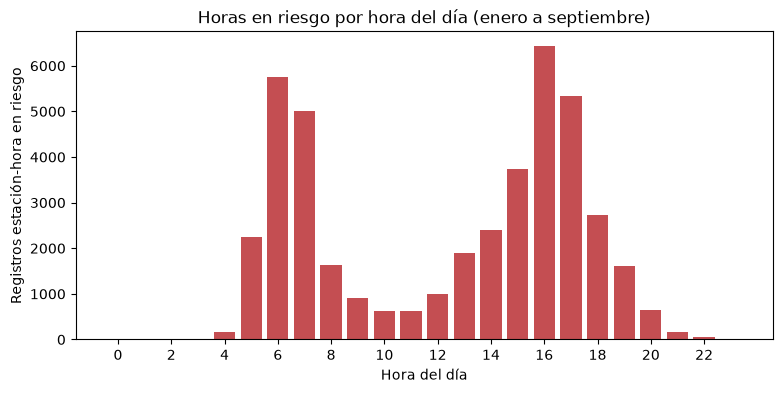

In [14]:
positivos = etiquetado[etiquetado["riesgo"] == 1]
print("Umbral:", config.UMBRAL_RIESGO, "| ventana:", config.VENTANA_RIESGO_HORAS, "h")
print("Estaciones con alguna hora en riesgo:", positivos["estacion_id"].nunique(), "de", etiquetado["estacion_id"].nunique())
print("Tienden a llenarse:", int((positivos["neto_futuro"] > 0).sum()), "| tienden a vaciarse:", int((positivos["neto_futuro"] < 0).sum()))
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(range(24), positivos["hora"].dt.hour.value_counts().reindex(range(24), fill_value=0).values, color="#C44E52")
ax.set_title("Horas en riesgo por hora del día (enero a septiembre)")
ax.set_xlabel("Hora del día")
ax.set_ylabel("Registros estación-hora en riesgo")
ax.set_xticks(range(0, 24, 2))
plt.show()

## Perfiles de uso por estación (P3)

Estaciones con perfil: 369 | variables por estación: 98


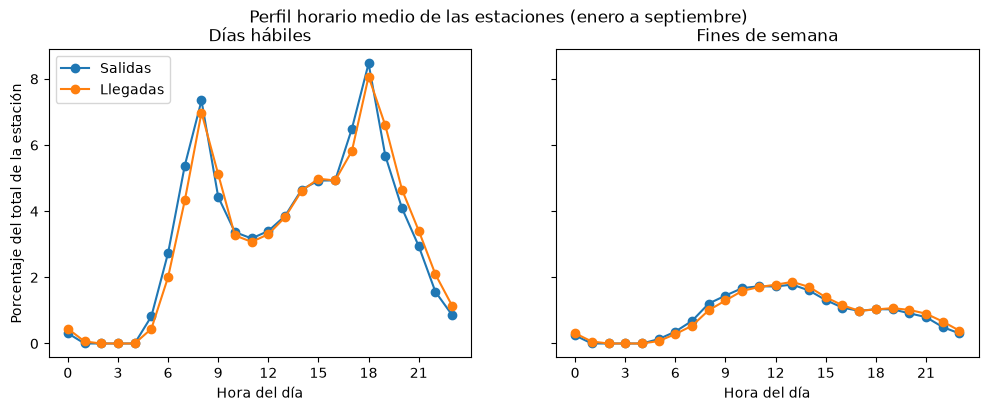

In [15]:
perfil = features.conjunto_p3(viajes, estaciones)
print("Estaciones con perfil:", len(perfil), "| variables por estación:", perfil.shape[1] - 4)
horas = range(24)
fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for eje, tipo, titulo in [(ax[0], "habil", "Días hábiles"), (ax[1], "finde", "Fines de semana")]:
    salidas_medias = perfil[[f"salidas_{tipo}_{h:02d}" for h in horas]].mean() * 100
    llegadas_medias = perfil[[f"llegadas_{tipo}_{h:02d}" for h in horas]].mean() * 100
    eje.plot(list(horas), salidas_medias.values, marker="o", label="Salidas")
    eje.plot(list(horas), llegadas_medias.values, marker="o", label="Llegadas")
    eje.set_title(titulo)
    eje.set_xlabel("Hora del día")
    eje.set_xticks(range(0, 24, 3))
ax[0].set_ylabel("Porcentaje del total de la estación")
ax[0].legend()
fig.suptitle("Perfil horario medio de las estaciones (enero a septiembre)")
plt.show()

In [16]:
columnas_habil = [c for c in perfil.columns if c.startswith("salidas_habil")]
variabilidad = (perfil[columnas_habil].std() * 100).sort_values(ascending=False)
print("Horas de días hábiles en las que más difieren las estaciones (desviación en puntos porcentuales):")
variabilidad.head(5).round(2)

Horas de días hábiles en las que más difieren las estaciones (desviación en puntos porcentuales):


salidas_habil_18    3.59
salidas_habil_08    3.41
salidas_habil_07    3.15
salidas_habil_17    2.66
salidas_habil_06    2.04
dtype: float64

El uso tiene dos picos en días hábiles (alrededor de las 7 y de las 17 h) y uno solo hacia el mediodía en fin de semana, y la demanda diaria por estación es muy dispar, por lo que P1 se plantea por estación con rezagos semanales. Con el umbral de la mitad de la capacidad en una ventana de dos horas, menos del 2 % de las horas-estación quedan en riesgo y se concentran en las horas pico, en los dos sentidos (llenarse y vaciarse). Las transformaciones de este notebook viven como funciones en `mibici/features.py`.